# 01 — Chapman-Shaoxing: Nested `RECORDS`, Header Integrity & Demographics (`45,152` Records)

Auditing all `45,152` Chapman-Shaoxing ECGs (`WFDBRecords/01..46/*`):
1. **Nested `RECORDS` Fix**: Top-level `RECORDS` lists `452` subdirectories (`WFDBRecords/01/010/`), each containing a nested `RECORDS` file. Updating `CinCStyleDataset._expand_records` restored all `45,152` records.
2. **Header & Demographic Hygiene**: Missing/corrupt files, duration consistency (`5000` samples @ `500 Hz`), missing/invalid/pediatric ages, and sex balance.

Total Chapman-Shaoxing records : 45,053
  err_file_missing_or_corrupt       :    318 ( 0.71%)
  err_hdr_nonstandard_duration      :      0 ( 0.00%)
  err_hdr_nonstandard_fs_or_leads   :      1 ( 0.00%)
  err_age_missing                   :     55 ( 0.12%)
  err_age_invalid_or_sentinel       :    247 ( 0.55%)
  err_age_pediatric                 :  1,845 ( 4.10%)
  err_sex_missing_or_unknown        :     22 ( 0.05%)

Sex counts: {'Male': 25223, 'Female': 19490, '<empty>': 318, 'Unknown': 22}


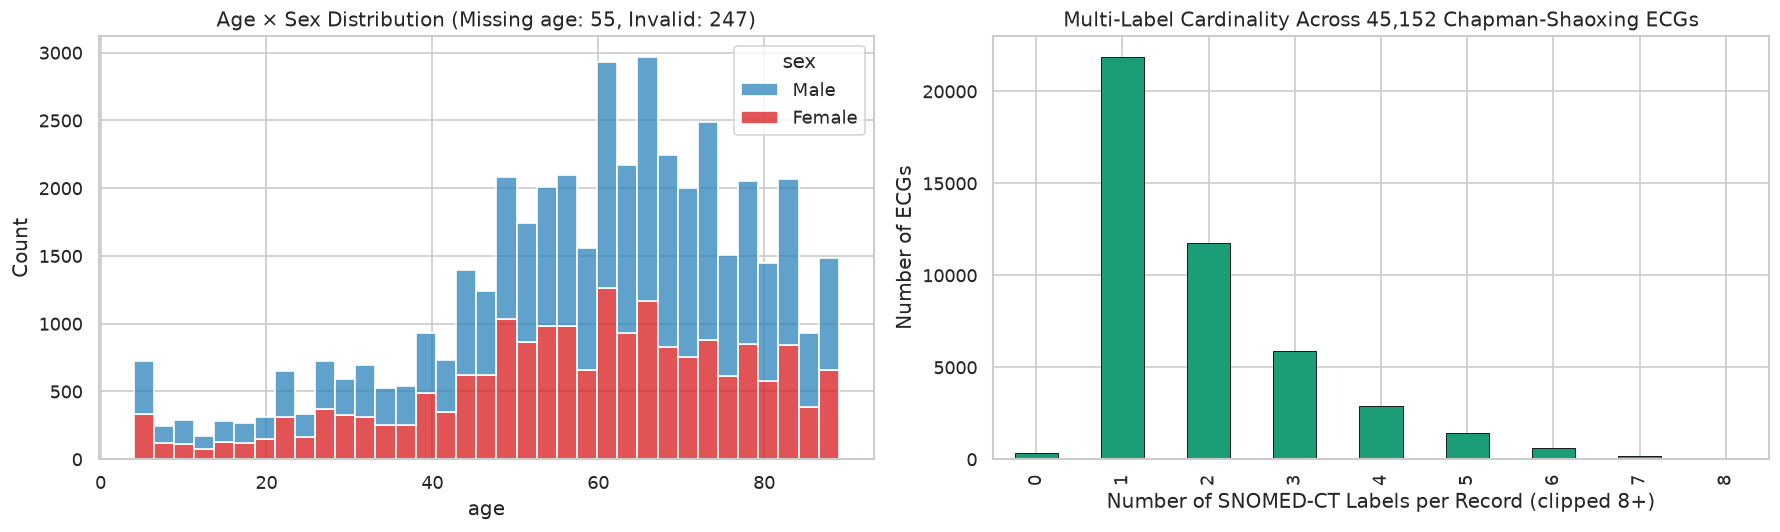

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "chapman_shaoxing" / "quality" / "error_labels.csv").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate chapman_shaoxing/quality/error_labels.csv from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from chapman_shaoxing import ChapmanShaoxingDataset

CHAPMAN_DIR = REPO_ROOT / "chapman_shaoxing"
DATA_DIR = CHAPMAN_DIR / "data"
QUALITY_DIR = CHAPMAN_DIR / "quality"
LEADS = ChapmanShaoxingDataset.LEADS

df = pd.read_csv(QUALITY_DIR / "error_labels.csv", index_col="record_id")
df["snomed_codes"] = df["snomed_codes"].fillna("")
df["label_names"] = df["label_names"].fillna("")
df["error_tags"] = df["error_tags"].fillna("")
df["sex"] = df["sex"].fillna("")

print(f"Total Chapman-Shaoxing records : {len(df):,}")
for col in [
    "err_file_missing_or_corrupt", "err_hdr_nonstandard_duration",
    "err_hdr_nonstandard_fs_or_leads", "err_age_missing",
    "err_age_invalid_or_sentinel", "err_age_pediatric", "err_sex_missing_or_unknown",
]:
    cnt = int(df[col].sum())
    print(f"  {col:<34}: {cnt:6,d} ({cnt/len(df)*100:5.2f}%)")

print("\nSex counts:", df["sex"].replace("", "<empty>").value_counts().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
age_ok = df[df["age"].between(1, 100) & df["sex"].isin(["Male", "Female"])]
sns.histplot(data=age_ok, x="age", hue="sex", bins=35, multiple="stack", palette={"Male": "#2b83ba", "Female": "#d7191c"}, ax=axes[0])
axes[0].set_title(f"Age × Sex Distribution (Missing age: {int(df['err_age_missing'].sum())}, Invalid: {int(df['err_age_invalid_or_sentinel'].sum())})")

df["n_dx_codes"].clip(upper=8).value_counts().sort_index().plot(kind="bar", color="#1b9e77", edgecolor="black", lw=0.5, ax=axes[1])
axes[1].set_xlabel("Number of SNOMED-CT Labels per Record (clipped 8+)")
axes[1].set_ylabel("Number of ECGs")
axes[1].set_title("Multi-Label Cardinality Across 45,152 Chapman-Shaoxing ECGs")

plt.tight_layout()
plt.show()